# Step 8: Hyperparameter tuning with batch-wise cross-validation

**Question:** how much does careful tuning improve each model, without ever touching the test batches?

**How the tuning was done** (`src/tuning.py`, run by `scripts/run_step8_tuning.py`):
- Only **batches 1-3** are used. Tuning is handed a table that contains no other batch.
- **Two forward-chaining folds** that copy the real task of predicting a later batch from earlier ones:
  train on batch 1 and validate on batch 2; train on batches 1-2 and validate on batch 3.
- Every configuration of a small grid is scored by its **mean macro-F1** over the two folds. The best one is chosen
  (ties: higher accuracy, then first in the grid).
- The chosen configuration is refitted on batches 1-3 and tested **once** on protocol A (batches 4-10).
- All 7 models x 3 options (no reduction, PCA, LDA) were tuned, i.e. 21 tuning runs.
- Tuned models are evaluated on **protocol A only**. Protocols B and C test on batches 2 and 3, which tuning used for
  validation, so they would not be a fair test of tuned settings.

In [1]:
import os
import sys
import json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import tuning

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)

def read(name):
    # keep_default_na=False: otherwise pandas turns the text "None" (no reduction) into a missing value
    return pd.read_csv(f"../results/{name}", keep_default_na=False)

cv = read("step8_tuning_cv.csv")
tuned = read("step8_tuned_protocolA.csv")
s5 = read("step5_baseline_metrics.csv"); s5["reduction"] = "None"
s6 = read("step6_reduction_metrics.csv"); s6 = s6[s6["reduction"].isin(["PCA", "LDA"])]
s7 = read("step7_boosting_metrics.csv")
untuned = pd.concat([s5, s6, s7], ignore_index=True)
untuned = untuned[untuned["protocol"] == "A"]

MODELS = tuning.ALL_MODELS
RED = ["None", "PCA", "LDA"]
print("configurations scored:", len(cv), "| tuned results rows:", len(tuned))
assert set(zip(cv["model"], cv["reduction"])) == {(m, r) for m in MODELS for r in RED}, "tuning is incomplete"
assert set(zip(tuned["model"], tuned["reduction"])) == {(m, r) for m in MODELS for r in RED}, "tuned evaluation is incomplete"

configurations scored: 270 | tuned results rows: 168


## 1. What was searched

In [2]:
grid_table = pd.DataFrame({
    "settings searched": {m: ", ".join(f"{k}: {v}" for k, v in tuning.GRIDS[m].items()) for m in MODELS},
    "configurations": {m: len(tuning.param_combos(m)) for m in MODELS},
})
grid_table

,settings searched,configurations
kNN,"n_neighbors: [1, 3, 5, 9, 15, 25], weights: ['uniform', 'distance']",12
SVM,"C: [0.1, 1, 10, 100], gamma: ['scale', 0.001, 0.01, 0.1]",16
Decision Tree,"max_depth: [3, 5, 10, 20, None], min_samples_leaf: [1, 5, 20]",15
Random Forest,"n_estimators: [100, 300], max_depth: [10, None], min_samples_leaf: [1, 5], m...",16
Naive Bayes,"var_smoothing: [1e-09, 1e-08, 1e-07, 1e-05, 0.001, 0.1, 1.0]",7
AdaBoost,"n_estimators: [50, 100, 200], learning_rate: [0.1, 0.5, 1.0], base_depth: [1...",18
Gradient Boosting,"n_estimators: [100, 200], max_depth: [2, 3, 5]",6


## 2. Chosen settings and their validation score

In [3]:
best = tuning.select_best(cv)
best_table = best[["model", "reduction", "params", "mean_macro_f1", "mean_accuracy"]].copy()
best_table["model"] = pd.Categorical(best_table["model"], MODELS, ordered=True)
best_table["reduction"] = pd.Categorical(best_table["reduction"], RED, ordered=True)
best_table = best_table.sort_values(["model", "reduction"]).reset_index(drop=True)
best_table.round(3).to_csv("../results/step8_best_params.csv", index=False)
best_table.round(3)

,model,reduction,params,mean_macro_f1,mean_accuracy
0,kNN,None,"{""n_neighbors"": 1, ""weights"": ""uniform""}",0.788,0.851
1,kNN,PCA,"{""n_neighbors"": 1, ""weights"": ""uniform""}",0.801,0.869
2,kNN,LDA,"{""n_neighbors"": 1, ""weights"": ""uniform""}",0.607,0.611
3,SVM,None,"{""C"": 100, ""gamma"": 0.01}",0.809,0.886
4,SVM,PCA,"{""C"": 1, ""gamma"": 0.1}",0.767,0.831
5,SVM,LDA,"{""C"": 0.1, ""gamma"": ""scale""}",0.628,0.622
6,Decision Tree,None,"{""max_depth"": 10, ""min_samples_leaf"": 1}",0.798,0.838
7,Decision Tree,PCA,"{""max_depth"": 5, ""min_samples_leaf"": 20}",0.685,0.784
8,Decision Tree,LDA,"{""max_depth"": 5, ""min_samples_leaf"": 5}",0.547,0.640
9,Random Forest,None,"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 1, ""max_feature...",0.794,0.837


**What to notice:** validation macro-F1 (on batches 2 and 3, which come right after the training data) is high
for the raw-feature models, around 0.72-0.81, and lower with LDA (0.50-0.68), because in fold 1 the LDA is fitted on
only 371 samples. **kNN picks `n_neighbors = 1` in all three settings:** on batches close in time, copying the single
nearest neighbour works best. SVM without reduction picks the more flexible `C = 100, gamma = 0.01`.

## 3. How sensitive is each model to its settings?

In [4]:
spread = cv.groupby(["model", "reduction"])["mean_macro_f1"].agg(["min", "max"])
spread["range"] = spread["max"] - spread["min"]
spread_t = spread["range"].unstack()[RED].loc[MODELS]
print("Range of validation macro-F1 across the grid (max minus min):")
spread_t.round(3)

Range of validation macro-F1 across the grid (max minus min):


reduction,None,PCA,LDA
model,,,
kNN,0.112,0.110,0.012
SVM,0.455,0.416,0.219
Decision Tree,0.034,0.100,0.144
Random Forest,0.033,0.020,0.006
Naive Bayes,0.153,0.377,0.145
AdaBoost,0.317,0.328,0.177
Gradient Boosting,0.069,0.037,0.259


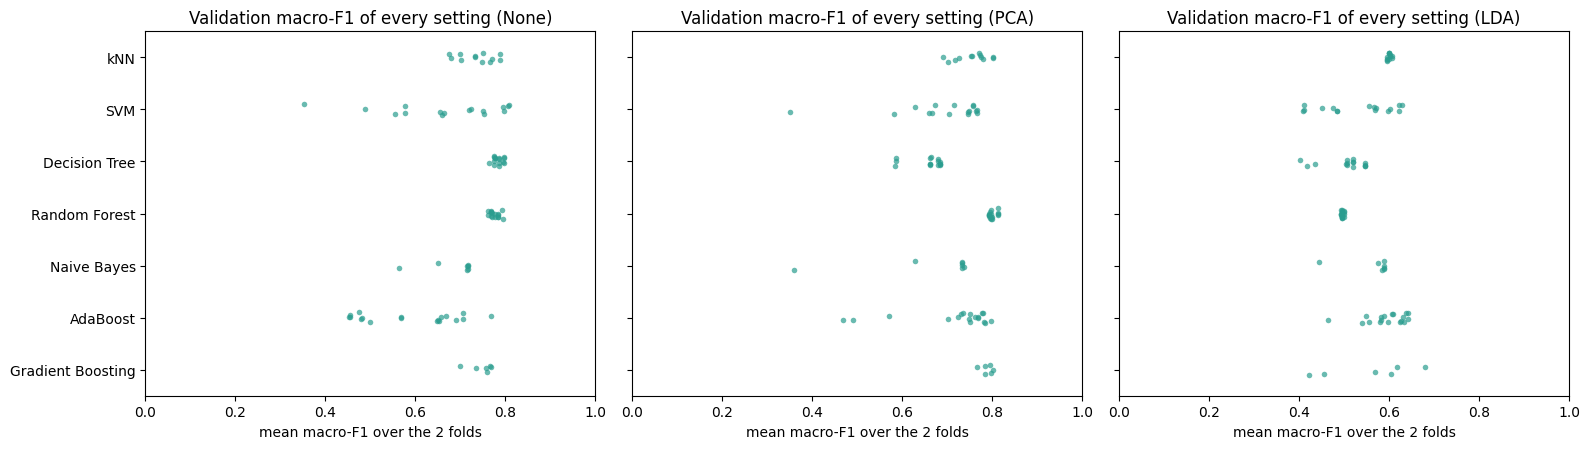

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, red in zip(axes, RED):
    d = cv[cv["reduction"] == red]
    sns.stripplot(data=d, y="model", x="mean_macro_f1", order=MODELS, ax=ax, size=4, alpha=0.7, color="#2a9d8f")
    ax.set_title(f"Validation macro-F1 of every setting ({red})"); ax.set_xlabel("mean macro-F1 over the 2 folds")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig("../results/step8_cv_landscape.png", dpi=150)
plt.show()

**What to notice:** the models differ a lot in how much their settings matter. **SVM is the most sensitive** (its
validation macro-F1 ranges over 0.46 without reduction and 0.42 with PCA between the worst and best setting),
followed by AdaBoost (about 0.32) and Naive Bayes with PCA (0.38). **Random Forest is the least sensitive** (at most
0.033 across its grid), and so is the Decision Tree without reduction (0.034). So a badly chosen
SVM can be much worse than a good one, while Random Forest is robust to its settings.

## 4. Tuned vs untuned on protocol A (test batches 4-10)

In [6]:
def pooled(frame):
    f = frame[frame["test_batch"] == "pooled"]
    return f.set_index(["model", "reduction"])[["accuracy", "macro_f1"]]

u, t = pooled(untuned), pooled(tuned)
cmp = pd.DataFrame({
    "untuned accuracy": u["accuracy"], "tuned accuracy": t["accuracy"],
    "untuned macro-F1": u["macro_f1"], "tuned macro-F1": t["macro_f1"],
}).loc[[(m, r) for m in MODELS for r in RED]]
cmp["accuracy change"] = cmp["tuned accuracy"] - cmp["untuned accuracy"]
cmp["macro-F1 change"] = cmp["tuned macro-F1"] - cmp["untuned macro-F1"]
cmp.round(3).to_csv("../results/step8_tuned_vs_untuned.csv")
cmp.round(3)

untuned accuracy  tuned accuracy  untuned macro-F1  tuned macro-F1  accuracy change  macro-F1 change
model             reduction                                                                                                      
kNN               None                  0.696           0.669             0.707           0.684           -0.028           -0.023
                  PCA                   0.683           0.649             0.693           0.663           -0.034           -0.031
                  LDA                   0.669           0.662             0.677           0.675           -0.006           -0.002
SVM               None                  0.727           0.732             0.740           0.745            0.005            0.006
                  PCA                   0.670           0.669             0.695           0.673           -0.002           -0.022
                  LDA                   0.661           0.699             0.672           0.689            0.038            0.017
Decision Tree     None                  0.497           0.497             0.466           0.466            0.000            0.000
                  PCA                   0.530           0.561             0.515           0.543            0.031            0.028
                  LDA                   0.617           0.608             0.609           0.614           -0.009            0.006
Random Forest     None                  0.647           0.665             0.617           0.646            0.018            0.029
                  PCA                   0.704           0.695             0.683           0.672           -0.009           -0.011
                  LDA                   0.677           0.669             0.674           0.667           -0.008           -0.007
Naive Bayes       None                  0.565           0.565             0.567           0.567            0.000            0.000
                  PCA                   0.521           0.514             0.509           0.505           -0.008           -0.004
                  LDA                   0.716           0.716             0.716           0.716            0.000            0.000
AdaBoost          None                  0.472           0.546             0.452           0.516            0.074            0.065
                  PCA                   0.712           0.662             0.683           0.646           -0.050           -0.036
                  LDA                   0.610           0.610             0.622           0.622            0.000            0.000
Gradient Boosting None                  0.558           0.558             0.547           0.547            0.000            0.000
                  PCA                   0.687           0.677             0.682           0.671           -0.010           -0.011
                  LDA                   0.592           0.637             0.612           0.644            0.044            0.032

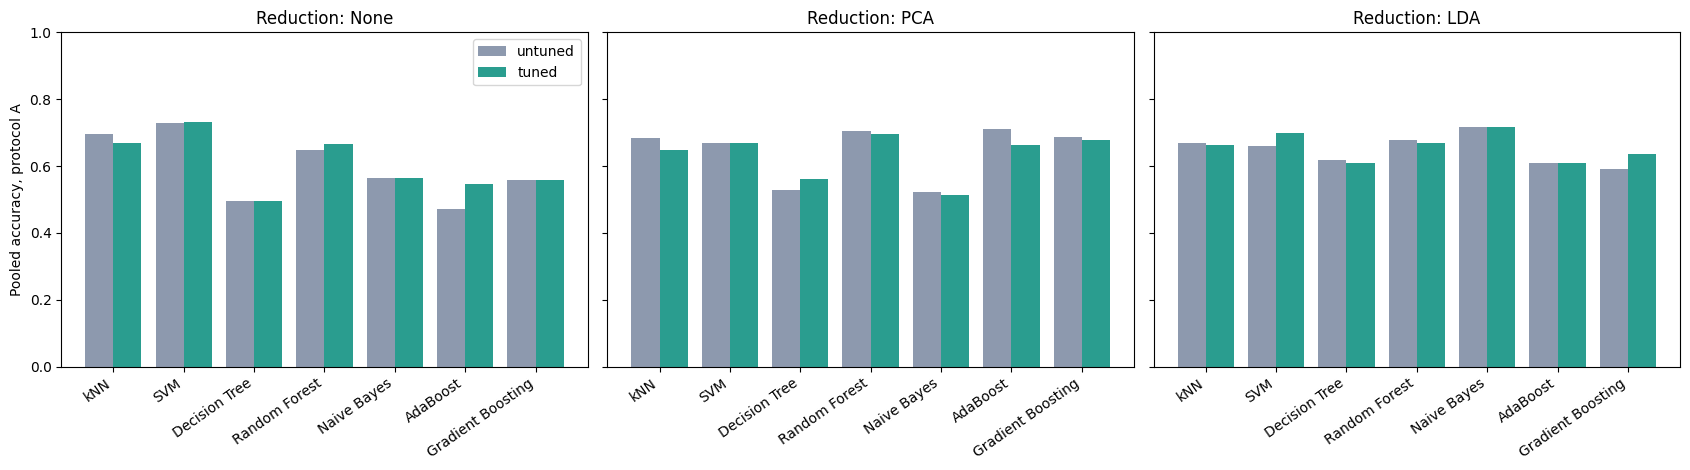

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
x = np.arange(len(MODELS))
for ax, red in zip(axes, RED):
    ax.bar(x - 0.2, [u.loc[(m, red), "accuracy"] for m in MODELS], 0.4, label="untuned", color="#8d99ae")
    ax.bar(x + 0.2, [t.loc[(m, red), "accuracy"] for m in MODELS], 0.4, label="tuned", color="#2a9d8f")
    ax.set_xticks(x); ax.set_xticklabels(MODELS, rotation=35, ha="right")
    ax.set_title(f"Reduction: {red}"); ax.set_ylim(0, 1)
axes[0].set_ylabel("Pooled accuracy, protocol A"); axes[0].legend()
plt.tight_layout()
plt.savefig("../results/step8_tuned_vs_untuned.png", dpi=150)
plt.show()

In [8]:
ch = cmp["accuracy change"] * 100
print(f"Of {len(ch)} model/reduction combinations (accuracy change in percentage points):")
print(f"  better by more than 0.5 points : {(ch > 0.5).sum()}")
print(f"  within +/-0.5 points (about same): {(ch.abs() <= 0.5).sum()}")
print(f"  worse by more than 0.5 points  : {(ch < -0.5).sum()}")
print(f"  mean change {ch.mean():+.2f}, median {ch.median():+.2f}, largest gain {ch.max():+.1f}, largest loss {ch.min():+.1f}")
print("kNN chose n_neighbors =", sorted({json.loads(p)["n_neighbors"] for p in best[best["model"] == "kNN"]["params"]}), "in all three reduction settings")

Of 21 model/reduction combinations (accuracy change in percentage points):
  better by more than 0.5 points : 5
  within +/-0.5 points (about same): 7
  worse by more than 0.5 points  : 9
  mean change +0.22, median +0.00, largest gain +7.4, largest loss -5.0
kNN chose n_neighbors = [1] in all three reduction settings


In [9]:
top = pd.DataFrame({"pooled accuracy": t["accuracy"], "pooled macro-F1": t["macro_f1"]}).sort_values("pooled accuracy", ascending=False)
print("Top 8 tuned combinations (protocol A):")
top.head(8).round(3)

Top 8 tuned combinations (protocol A):


,,pooled accuracy,pooled macro-F1
model,reduction,,
SVM,None,0.732,0.745
Naive Bayes,LDA,0.716,0.716
SVM,LDA,0.699,0.689
Random Forest,PCA,0.695,0.672
Gradient Boosting,PCA,0.677,0.671
SVM,PCA,0.669,0.673
kNN,None,0.669,0.684
Random Forest,LDA,0.669,0.667


In [10]:
print("Best untuned combinations for comparison:")
pd.DataFrame({"pooled accuracy": u["accuracy"], "pooled macro-F1": u["macro_f1"]}).sort_values("pooled accuracy", ascending=False).head(5).round(3)

Best untuned combinations for comparison:


,,pooled accuracy,pooled macro-F1
model,reduction,,
SVM,None,0.727,0.740
Naive Bayes,LDA,0.716,0.716
AdaBoost,PCA,0.712,0.683
Random Forest,PCA,0.704,0.683
kNN,None,0.696,0.707


**What to notice (protocol A, pooled accuracy):**
- **Tuning barely helps on the test batches.** Of the 21 model/reduction combinations, 5 improved by more than
  0.5 points, 7 stayed about the same and **9 got worse**. The mean change is +0.22 points and the median is 0.
- **The best result is essentially unchanged:** SVM with no reduction goes from 72.7% to **73.2%** (macro-F1 74.0% to
  74.5%). It is still the best model. Naive Bayes + LDA (71.6%) is unchanged, and the third place is now SVM + LDA (69.9%).
- **Largest gain:** AdaBoost without reduction, +7.4 points (47.2% to 54.6%), but it is still a weak model.
  **Largest loss:** AdaBoost + PCA, -5.0 points (71.2% to 66.2%), which drops it out of the top group.
  kNN gets worse in all three settings (-2.8, -3.4 and -0.6 points).
- **Note:** the "untuned" settings (library defaults) were fixed in advance, and the tuned settings were chosen only
  from batches 1-3. Neither was picked using the test batches, and we do not switch to whichever looks better on the
  test batches.

## 5. Per-batch effect of tuning

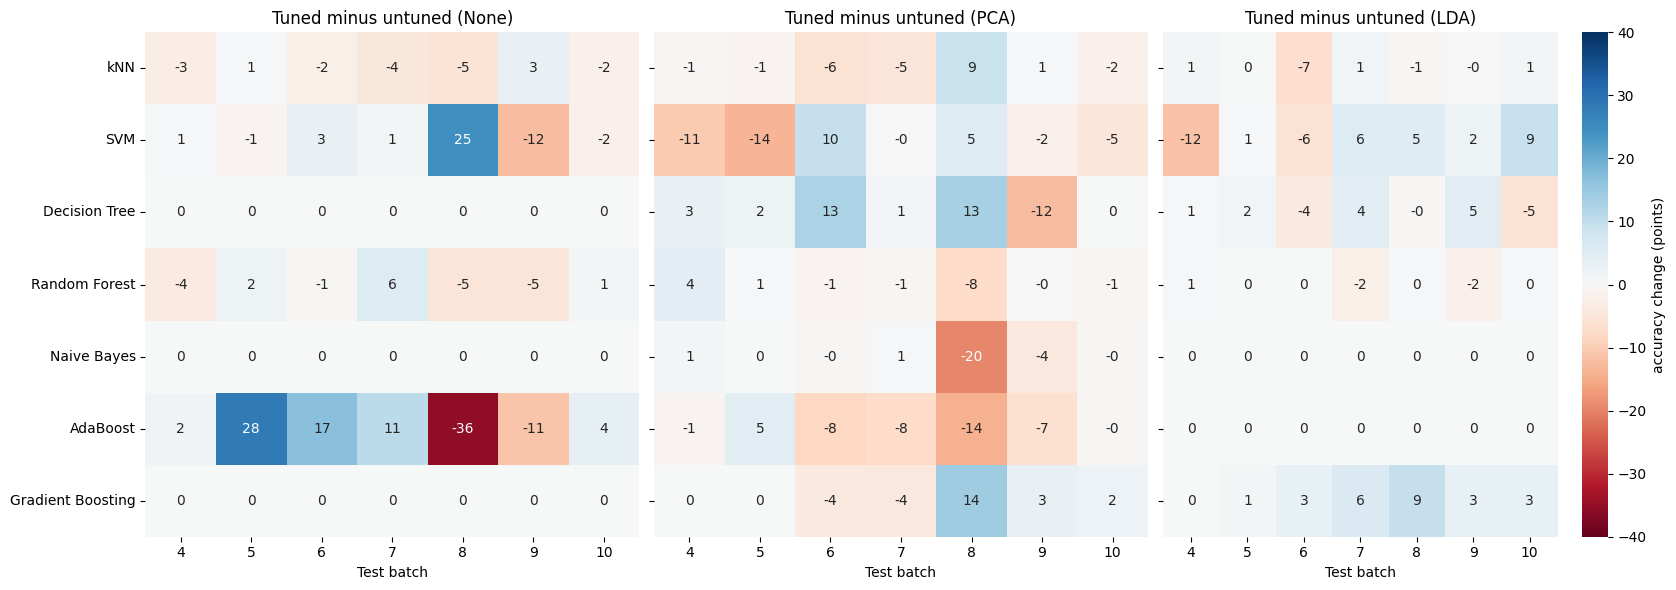

In [11]:
def per_batch(frame):
    f = frame[frame["test_batch"] != "pooled"].copy()
    f["test_batch"] = f["test_batch"].astype(int)
    return f.pivot_table(index=["model", "reduction"], columns="test_batch", values="accuracy")

delta = (per_batch(tuned) - per_batch(untuned)) * 100
fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
for ax, red in zip(axes, RED):
    d = delta.xs(red, level="reduction").loc[MODELS]
    sns.heatmap(d, annot=True, fmt=".0f", cmap="RdBu", center=0, vmin=-40, vmax=40, ax=ax,
                cbar=(red == "LDA"), cbar_kws={"label": "accuracy change (points)"})
    ax.set_title(f"Tuned minus untuned ({red})"); ax.set_xlabel("Test batch"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../results/step8_delta_per_batch.png", dpi=150)
plt.show()

**What to notice:** tuning moves individual batches a lot in both directions, even when the pooled change is small.
For example, SVM with no reduction gains 25 points on batch 8 but loses 12 on batch 9; AdaBoost with no reduction gains
28 points on batch 5 but loses 36 on batch 8; Naive Bayes + PCA loses 20 on batch 8. Cells that show 0 are models whose
tuned setting equals the default (Naive Bayes without reduction and with LDA, Gradient Boosting without reduction,
AdaBoost with LDA) or, for the Decision Tree without reduction, gives identical predictions. Batch 8 is the most affected, which fits its small size (276 samples).

## 6. Does the validation score predict the test score?

Correlation across the 21 model/reduction combinations: -0.14
Average validation minus test macro-F1: 0.089


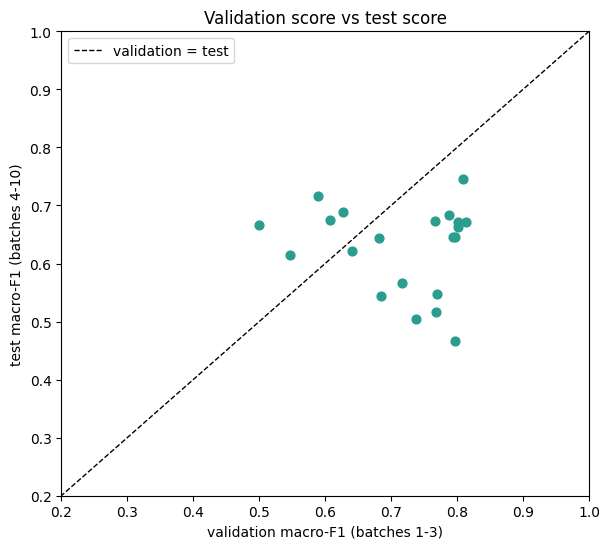

In [12]:
check = pd.DataFrame({
    "validation macro-F1 (batches 1-3)": best.set_index(["model", "reduction"])["mean_macro_f1"],
    "test macro-F1 (batches 4-10)": t["macro_f1"],
}).dropna()
corr = check.corr().iloc[0, 1]
print(f"Correlation across the 21 model/reduction combinations: {corr:.2f}")
print(f"Average validation minus test macro-F1: {(check.iloc[:, 0] - check.iloc[:, 1]).mean():.3f}")

fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.scatter(check.iloc[:, 0], check.iloc[:, 1], color="#2a9d8f", s=40)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="validation = test")
ax.set_xlim(0.2, 1); ax.set_ylim(0.2, 1)
ax.set_xlabel("validation macro-F1 (batches 1-3)"); ax.set_ylabel("test macro-F1 (batches 4-10)")
ax.set_title("Validation score vs test score"); ax.legend()
plt.tight_layout()
plt.savefig("../results/step8_validation_vs_test.png", dpi=150)
plt.show()

**What to notice:** points would lie on the dashed line if the validation score predicted the test score. They do not.
- Validation macro-F1 is on average **8.9 points higher** than test macro-F1, because the validation batches (2 and 3)
  are close in time to the training data, while the test batches are further away and have drifted more.
- Across the 21 combinations, the **correlation between validation and test score is -0.14**, i.e. essentially none.
  For example, the Decision Tree without reduction scores 0.80 on validation but only 0.47 on the test batches.
- So a setting that looks best on near-in-time batches is not reliably best on far-in-time batches. A plausible reason
  tuning does not help here (and picks k = 1 for kNN) is that near-in-time validation rewards fitting the training
  period closely, which is not what drift needs. We did not test this explanation directly.

## Summary of Step 8
- Every model was tuned with forward-chaining cross-validation on batches 1-3 only (270 configurations in total,
  21 tuning runs); the test batches were never used for any choice.
- **Tuning barely changed the results:** 5 combinations improved, 7 were about the same and 9 got worse (mean +0.22
  points). The best model is still SVM with no reduction, 72.7% to 73.2% pooled accuracy (macro-F1 74.5%).
- SVM is the most sensitive to its settings and Random Forest the least.
- **Validation scores do not predict test scores** (correlation -0.14, validation 8.9 points too optimistic), because
  drift makes later batches differ from the validation batches. This is itself a drift finding.
- Limits: only two validation folds, small grids, one run, tuned models tested on protocol A only, and no confidence
  intervals yet (Step 10).